# MATH 616: Computational Linear Algebra
## Deep Implicit Layers 1: Introduction, your first implicit layer

Lecture notebook, Fall 2026. Dr. Xuping Xie, Old Dominion University.

This is one of five lecture notebooks that follow the NeurIPS 2020 tutorial *Deep Implicit Layers* by Zico Kolter, David Duvenaud and Matt Johnson (implicit-layers-tutorial.org) chapter by chapter:

| | Notebook | Tutorial chapter |
|---|---|---|
| 1 | Introduction: your first implicit layer | Introduction |
| 2 | Implicit functions and automatic differentiation | Chapter 2 |
| 3 | Neural ordinary differential equations | Chapter 3 |
| 4 | Deep equilibrium models | Chapter 4 |
| 5 | Differentiable optimization | Chapter 5 |

The notebooks keep the tutorial's story, examples and code, translated to PyTorch, and add the explanations a mathematics student needs along the way. Paragraphs marked **Connection to MATH 616** point out where something from this course (iterative methods, Krylov methods, the SVD, eigenvalues, conditioning) is doing the work behind the scenes. Cells marked **Observe** say what to look for in the output just above them; cells marked ✏️ are for you to edit. Two substitutions keep everything laptop-sized: the scikit-learn $8\times8$ handwritten digits replace MNIST and CIFAR-10, and the tutorial's JAX code is written in PyTorch (`torch.func` for Jacobian products, a hand-written Runge–Kutta integrator in place of `odeint`).

**Learning goals for this notebook.** After working through it you should be able to

1. explain the difference between an *explicit* layer (a program) and an *implicit* layer (a condition), and give the three families of conditions;
2. implement a fixed-point layer $z = \tanh(Wz + x)$, solve it by forward iteration and by Newton's method, and say when each converges;
3. derive implicit differentiation for $g(x, z^\star) = 0$ and explain why the gradient depends only on the solution;
4. implement the tutorial's three-step *hook trick* (solve, re-engage, hook) in PyTorch and check it with `gradcheck`;
5. connect the convergence of the forward iteration to the spectral radius of the Jacobian, as in the iterative-methods unit.

## 0. Imports, data and helpers

In [ ]:
import numpy as np
import torch, torch.nn as nn
from torch import autograd
from torch.func import jvp, vjp, jacrev
import matplotlib.pyplot as plt
import time, warnings
warnings.filterwarnings("ignore", category=FutureWarning)

torch.set_num_threads(1)        # avoids an OpenMP clash between PyTorch and NumPy/MKL on some macOS installs
torch.manual_seed(616); np.random.seed(616)
torch.set_default_dtype(torch.float32)
print("torch", torch.__version__)

from sklearn.datasets import load_digits

# Digits: 1797 images of 8x8 pixels, 10 classes. Standardized features, 1400 train / 397 test.
digits = load_digits()
X = torch.tensor(digits.data / 16.0, dtype=torch.float32); X = (X - X.mean(0)) / (X.std(0) + 1e-6)
y = torch.tensor(digits.target)
perm = torch.randperm(len(X)); tr, te = perm[:1400], perm[1400:]
Xtr, ytr, Xte, yte = X[tr], y[tr], X[te], y[te]
print("train", tuple(Xtr.shape), "test", tuple(Xte.shape))

fig, axs = plt.subplots(1, 10, figsize=(8, 1.2))
for i, ax in enumerate(axs):
    ax.imshow(digits.images[i], cmap="gray_r"); ax.set_title(digits.target[i], fontsize=9); ax.axis("off")
plt.show()

In [ ]:
def epoch(Xd, yd, model, opt=None, batch=100, monitor=None):
    "One pass over the data (train if opt is given). Returns error rate, loss, and the mean of the monitored quantity."
    total_loss = total_err = total_mon = 0.0
    model.train() if opt else model.eval()
    for i in range(0, len(Xd), batch):
        xb, yb = Xd[i:i + batch], yd[i:i + batch]
        out = model(xb)
        loss = nn.functional.cross_entropy(out, yb)
        if opt:
            opt.zero_grad(); loss.backward()
            if any(torch.isnan(p.grad).any() for p in model.parameters() if p.grad is not None):
                continue                                                     # skip NaN updates, as in the tutorial
            opt.step()
        total_err += (out.argmax(1) != yb).sum().item(); total_loss += loss.item() * len(xb)
        if monitor is not None: total_mon += monitor() * len(xb)
    return total_err / len(Xd), total_loss / len(Xd), total_mon / len(Xd)


def train_model(model, epochs=10, lr=0.1, monitor=None, label=""):
    "SGD for `epochs` epochs, learning rate divided by 10 halfway, as in the tutorial's MNIST loop."
    opt = torch.optim.SGD(model.parameters(), lr=lr)
    t0 = time.time(); history = []
    for ep in range(1, epochs + 1):
        if ep == epochs // 2 + 1:
            for g in opt.param_groups: g["lr"] = lr / 10                     # drop the learning rate halfway
        tr_err, tr_loss, tr_mon = epoch(Xtr, ytr, model, opt, monitor=monitor)
        te_err, te_loss, te_mon = epoch(Xte, yte, model, monitor=monitor)
        history.append((ep, tr_err, te_err, te_mon))
        if ep in (1, 2, epochs // 2, epochs):
            print(f"{label} epoch {ep:2d}: train err {tr_err:.3f} loss {tr_loss:.3f} | test err {te_err:.3f} loss {te_loss:.3f}"
                  + (f" | {monitor.__name__} {te_mon:.1f}" if monitor else ""))
    print(f"{label} done in {time.time() - t0:.1f} s")
    return te_err, history

## 1.1 Explicit layers: layers as programs

Deep learning models are built by stacking *layers*: a convolution followed by a nonlinearity and a normalization, a residual block, a Transformer block with self-attention and a small fully connected network. Almost all of these layers are **explicit**: a layer is a fixed recipe of operations that turns its input into its output. A fully connected layer is

$$z = \sigma(Wx + b).$$

A (simplified) self-attention layer takes matrices $K, Q, V \in \mathbb{R}^{T\times n}$ of keys, queries and values and returns

$$Z = \operatorname{softmax}\!\Big(\frac{KQ^T}{\sqrt n}\Big)V .$$

In code, an explicit layer is just a function: compute this, then that, return the result. This way of thinking is so ingrained that it is hard to imagine a layer defined any other way. That is exactly what this tutorial does.

## 1.2 Implicit layers: layers as conditions

An **implicit** layer does not say how to compute its output. It says what the output must *satisfy*. Given an input $x$, the output is the vector $z$ that solves

$$g(x, z) = 0 \tag{1.1}$$

for some function $g$ chosen by the designer. The layer is defined by a condition, and some solver, which is not part of the definition, finds the $z$ that meets it.

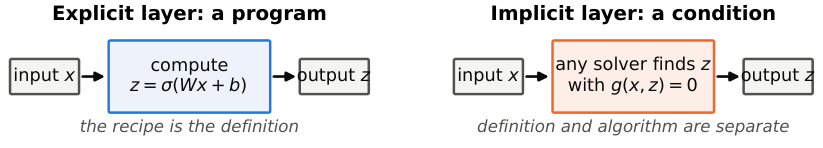

> **Intuition.** You already know implicit definitions from elsewhere in mathematics. The square root of $x$ is "the nonnegative number $z$ with $z^2 = x$", not a formula; a calculator finds it by an iteration. The solution of a linear system is "the $z$ with $Az = x$"; we never write $A^{-1}x$ in code, we call a solver. A planet's position at time $T$ is "what you get by following Newton's equations from the initial conditions"; an integrator computes it. In all three cases the *definition* (a condition) and the *algorithm* (a solver) are separate things, and that separation is the whole point of implicit layers.

Three families of conditions cover most of the field, and they are the three main chapters of the tutorial:

* **Algebraic equations and fixed points.** $g(x,z) = z - f(x,z)$: the output is a fixed point $z = f(x,z)$. This is the oldest idea (recurrent backpropagation, Almeida 1987 and Pineda 1987) and the modern one (deep equilibrium models, Bai, Kolter and Koltun 2019). Notebook 4.
* **Differential equations.** The output is the state at time $T$ of an ODE $\dot y = f(y, t)$ started at $y(0) = x$. These are neural ODEs (Chen et al. 2018). Notebook 3.
* **Optimality conditions of an optimization problem.** The output is $z = \arg\min_z \phi(z, x)$, characterized by $\nabla_z\phi = 0$ or, with constraints, by the KKT conditions. These are differentiable optimization layers (OptNet, cvxpylayers). Notebook 5.

**Why would anyone want this?** The tutorial gives two reasons, and both will come back in every chapter.

1. *Modularity.* The layer's definition is separated from the procedure that solves it. You can use a sophisticated off-the-shelf ODE solver or convex optimizer, swap it for another, and compare solvers objectively by how well they satisfy the condition $g = 0$. Nobody has to hand-derive a backward pass for each solver.
2. *Memory and accuracy.* If you solve the condition by an iterative method inside an autodiff framework and simply backpropagate through all the iterations, you must store every intermediate iterate: memory grows with the number of iterations. The implicit function theorem (Notebook 2) lets you compute the gradient *at the solution only*, with no memory of how you got there. This is often more accurate as well, because you differentiate the exact condition instead of a truncated iteration.

A third reason appears in practice: *adaptivity*. An explicit network has a fixed depth; an implicit layer's solver takes as many steps as the input needs, and a tolerance parameter trades speed for precision after training, with no retraining.

**What people have built with them.** The tutorial lists, as a sample: differentiable solutions of structured convex problems (through the `cvxpy` library); smoothed relaxations of combinatorial problems such as graph cuts and satisfiability; differential equations as layers, for continuous-time data and continuous-depth residual networks; architectures for representing smooth probability densities (normalizing flows); and equilibrium models that match Transformers of the same parameter count on language modeling and match leading vision architectures on classification and segmentation.

## 1.3 Your first implicit model: a fixed-point layer

The tutorial's first example is deliberately simple. Take a weight matrix $W \in \mathbb{R}^{n\times n}$ and define the layer's output as the vector $z$ with

$$z = \tanh(Wz + x), \tag{1.2}$$

that is, the root of $g(x, z) = z - \tanh(Wz + x)$. Where does such a condition come from? Imagine a very deep network in which *every* layer is the same, $z_{k+1} = \tanh(Wz_k + x)$, with the input $x$ fed into every layer. If the sequence $z_k$ settles down, its limit satisfies (1.2): the fixed-point layer is an **infinitely deep weight-tied network**, with the depth replaced by a convergence test.

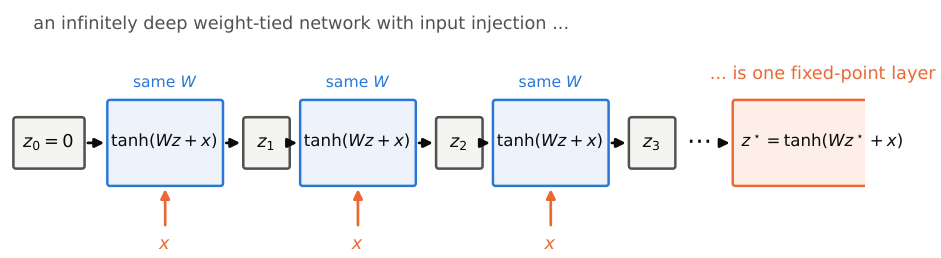

> **Intuition.** Think of $z \mapsto \tanh(Wz + x)$ as a "correction step" that nudges the current guess. If each correction is smaller than the last (the map is a contraction), the guesses converge to a point that no longer moves: the fixed point. The simplest solver is to apply the correction until nothing changes. The figure below shows this in one dimension: the iteration bounces between the graph of $f$ and the diagonal and homes in on the crossing when $f$ is flat enough, and bounces forever when it is too steep.

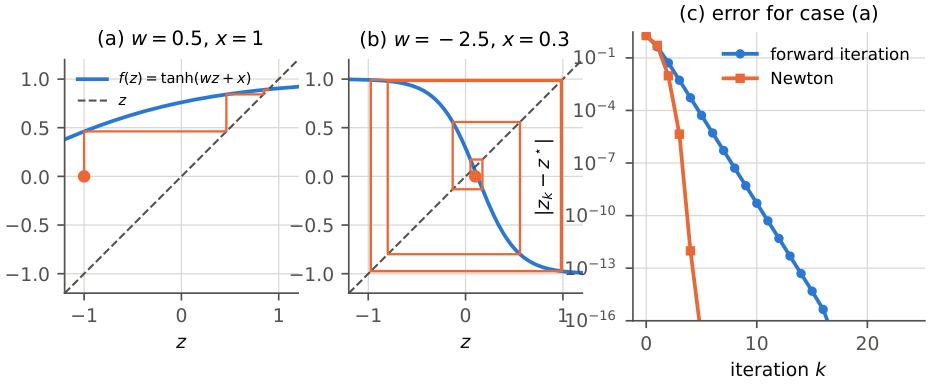

*(a) With $w = \tfrac12$ and $x = 1$ the map is a contraction and the iteration converges to $z^\star \approx 0.8952$. (b) With $w = -2.5$ the slope at the crossing exceeds one in size and the iteration settles into a two-cycle instead. (c) For case (a), the error of forward iteration decreases by the constant factor $|f'(z^\star)| \approx 0.1$ per step, while Newton's method (Section 1.4) converges quadratically.*

Here is the tutorial's PyTorch implementation of the layer. The loop stops when two successive iterates differ by less than `tol` or after `max_iter` steps.

In [ ]:
class TanhFixedPointLayer(nn.Module):
    def __init__(self, out_features, tol=1e-4, max_iter=50):
        super().__init__()
        self.linear = nn.Linear(out_features, out_features, bias=False)
        self.tol, self.max_iter = tol, max_iter

    def forward(self, x):
        z = torch.zeros_like(x)
        self.iterations = 0
        while self.iterations < self.max_iter:
            z_next = torch.tanh(self.linear(z) + x)
            self.err = torch.norm(z - z_next)
            z = z_next
            self.iterations += 1
            if self.err < self.tol:
                break
        return z

layer = TanhFixedPointLayer(50)
Xr = torch.randn(10, 50)
Z = layer(Xr)
print(f"terminated after {layer.iterations} iterations with error {layer.err:.2e}")

**Observe.** On random inputs the iteration settles in a dozen or so steps (the tutorial reports about 15 iterations to an error of $5\times10^{-5}$ on a random 50-dimensional input).

Now put the layer inside a classifier, exactly as the tutorial does for MNIST: a linear layer into the fixed-point layer, then a linear read-out. The tutorial trains with SGD for ten epochs at learning rate $0.1$, dropped to $0.01$ halfway; its loop skips any update whose gradients contain NaNs, a hint that the forward iteration does not always converge; and it monitors the number of iterations, which grows during training. We do all three.

In [ ]:
torch.manual_seed(0)
model_fp = nn.Sequential(nn.Linear(64, 100), TanhFixedPointLayer(100, max_iter=200), nn.Linear(100, 10))
def iterations(): return model_fp[1].iterations
err_fp, hist_fp = train_model(model_fp, epochs=10, lr=0.1, monitor=iterations, label="fixed-point layer")

plt.figure(figsize=(5, 2.8)); plt.plot([h[0] for h in hist_fp], [h[3] for h in hist_fp], "o-")
plt.xlabel("epoch"); plt.ylabel("forward iterations (test set mean)"); plt.grid(alpha=.3); plt.title("The iteration count grows during training"); plt.tight_layout(); plt.show()

**Observe.** The network learns the digits well (test error around 5%), and the iteration count on the test set rises as training proceeds. The tutorial sees the same thing on MNIST.

**Connection to MATH 616.** The loop above is the stationary iteration $z \leftarrow Mz + c$ from the iterative-methods unit with the nonlinear map $\tanh(Wz + x)$ in place of $Mz + c$. It converges for every start if the map is a contraction, for instance if $\|W\|_2 < 1$ (because $\tanh$ never stretches distances), and the rate of convergence near the fixed point is governed by the spectral radius of the Jacobian

$$J = \operatorname{diag}(1 - z^{\star 2})\, W,$$

exactly as $\rho(M)$ governed Jacobi and Gauss–Seidel. When training makes $W$ larger, the iteration slows down and can stop converging; this is what the NaN check is for. The figure below (from a run of this same experiment) shows the matrix behind the growing iteration count. Let us measure $\|W\|_2$ and $\rho(J)$ of our trained layer.

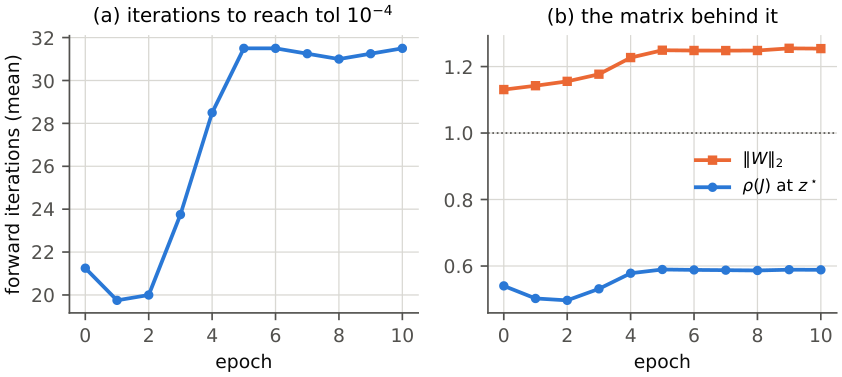

In [ ]:
W = model_fp[1].linear.weight.detach()
with torch.no_grad():
    xb = model_fp[0](Xte[:5]); zs = model_fp[1](xb)
rhos = [torch.linalg.eigvals(torch.diag(1 - zs[i]**2) @ W).abs().max().item() for i in range(5)]
print(f"||W||_2 = {torch.linalg.matrix_norm(W, 2):.3f}   rho(J) at five test equilibria: {np.round(rhos, 3)}")
print("The 2-norm bound is useless (> 1), but rho(J) < 1: the iteration still converges, just more slowly than at initialization.")

## 1.4 Alternative root finders: Newton's method

Nothing says the fixed point must be found by repeating the map. Since the layer is defined by $g(x, z) = 0$, any root finder will do. Newton's method is

$$z \leftarrow z - \Big(\frac{\partial g}{\partial z}\Big)^{-1} g(x, z), \qquad \frac{\partial g}{\partial z} = I - \operatorname{diag}\big(\tanh'(Wz + x)\big)\, W, \qquad \tanh'(s) = 1 - \tanh^2(s),$$

and the tutorial's `TanhNewtonLayer` forms this Jacobian explicitly (it is $n\times n$ with $n = 100$, one per input in the batch) and calls a dense solver each step.

In [ ]:
class TanhNewtonLayer(nn.Module):
    def __init__(self, out_features, tol=1e-4, max_iter=50):
        super().__init__()
        self.linear = nn.Linear(out_features, out_features, bias=False)
        self.tol, self.max_iter = tol, max_iter

    def forward(self, x):
        z = torch.tanh(x)
        self.iterations = 0
        while self.iterations < self.max_iter:
            z_linear = self.linear(z) + x
            g = z - torch.tanh(z_linear)
            self.err = torch.norm(g)
            if self.err < self.tol:
                break
            J = torch.eye(z.shape[1]) - (1 / torch.cosh(z_linear)**2)[:, :, None] * self.linear.weight[None]
            z = z - torch.linalg.solve(J, g[:, :, None])[:, :, 0]
            self.iterations += 1
        return z

layer = TanhNewtonLayer(50); Z = layer(Xr)
print(f"Newton terminated after {layer.iterations} iterations with error {layer.err:.2e}")

**Observe.** Three or four Newton steps instead of fifteen, and to a much smaller residual: Newton converges quadratically once it is close (compare panel (c) of the cobweb figure).

But watch what happens when we *train* this layer by backpropagating **through** the Newton iterations. The tutorial finds it slower and less stable than the fixed-point version, with roughly 5% of the updates producing NaN gradients. This is a first sign that differentiating through a solver is the wrong idea.

In [ ]:
torch.manual_seed(0)
model_newton = nn.Sequential(nn.Linear(64, 100), TanhNewtonLayer(100, max_iter=40), nn.Linear(100, 10))
def iterations(): return model_newton[1].iterations
err_newton, _ = train_model(model_newton, epochs=8, lr=0.1, monitor=iterations, label="Newton layer, unrolled")

## 1.5 Differentiation in implicit layers

Here is the key computation of the whole tutorial, in its simplest form. Suppose $z^\star(x)$ solves $g(x, z^\star) = 0$ for every $x$ near the one we care about. Differentiate this identity with respect to $x$ by the chain rule:

$$\frac{\partial g}{\partial x} + \frac{\partial g}{\partial z^\star}\frac{\partial z^\star}{\partial x} = 0
\qquad\Longrightarrow\qquad
\frac{\partial z^\star}{\partial x} = -\Big(\frac{\partial g}{\partial z^\star}\Big)^{-1}\frac{\partial g}{\partial x}.$$

This is **implicit differentiation**, the same trick as in calculus (differentiate $x^2 + z^2 = 1$ to get $dz/dx = -x/z$ without solving for $z$). For training we need the gradient of a scalar loss $\ell$ with respect to $x$, which by the chain rule again is

$$\nabla_x \ell = \Big(\frac{\partial g}{\partial x}\Big)^{T}\Big(\frac{\partial g}{\partial z^\star}\Big)^{-T}\nabla_{z^\star}\ell . \tag{1.3}$$

Two remarks. First, the formula involves only the solution $z^\star$, not the iterations that produced it: whether you used 3 Newton steps or 50 fixed-point steps, the gradient is the same, and nothing needs to be stored. Second, the inverse is never formed: one solves **one linear system** with the transposed Jacobian.

**Implementing it with a hook.** The tutorial's trick for putting this into PyTorch without writing a custom backward function has three steps:

1. Solve for $z^\star$ inside `torch.no_grad()`, so the solver leaves no trace in the computation graph.
2. "Re-engage" autograd by evaluating $z = z^\star - g(x, z^\star)$ once with gradient tracking on. Numerically $g(x, z^\star) = 0$ so the value is unchanged, but the graph now contains one copy of $g$, which gives autograd the factors $\partial g/\partial x$ (and $\partial g/\partial W$).
3. Register a backward hook on $z$. When the gradient $\nabla_z \ell$ arrives during backpropagation, the hook replaces it by the solution of the linear system with $(\partial g/\partial z^\star)^T$. Autograd then multiplies by $(\partial g/\partial x)^T$ on its own, which is exactly (1.3).

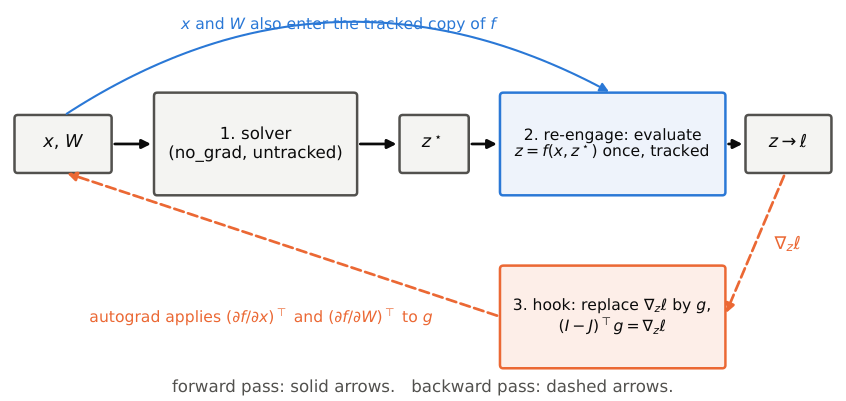

In [ ]:
class TanhNewtonImplicitLayer(nn.Module):
    def __init__(self, out_features, tol=1e-4, max_iter=50):
        super().__init__()
        self.linear = nn.Linear(out_features, out_features, bias=False)
        self.tol, self.max_iter = tol, max_iter

    def forward(self, x):
        # 1. Newton's method, outside the autograd tape
        with torch.no_grad():
            z = torch.tanh(x)
            self.iterations = 0
            while self.iterations < self.max_iter:
                z_linear = self.linear(z) + x
                g = z - torch.tanh(z_linear)
                self.err = torch.norm(g)
                if self.err < self.tol:
                    break
                J = torch.eye(z.shape[1]) - (1 / torch.cosh(z_linear)**2)[:, :, None] * self.linear.weight[None]
                z = z - torch.linalg.solve(J, g[:, :, None])[:, :, 0]
                self.iterations += 1
        # 2. re-engage autograd and add the gradient hook
        z = torch.tanh(self.linear(z) + x)
        z0 = z.clone().detach().requires_grad_()
        g0 = z0 - torch.tanh(self.linear(z0) + x)
        J = torch.eye(z.shape[1]) - (1 / torch.cosh(self.linear(z0) + x)**2)[:, :, None] * self.linear.weight[None]
        # 3. the hook replaces the gradient v by (dg/dz)^{-T} v
        if z.requires_grad:
            z.register_hook(lambda grad: torch.linalg.solve(J.transpose(1, 2), grad[:, :, None])[:, :, 0] if grad is not None else None)
        return z

layer = TanhNewtonImplicitLayer(5).double()
gradcheck_ok = autograd.gradcheck(lambda x: layer(x).sum(), torch.randn(3, 5, dtype=torch.double, requires_grad=True), check_undefined_grad=False)
print("gradcheck:", gradcheck_ok)

**Observe.** `torch.autograd.gradcheck` compares the hook's gradient with finite differences in double precision and returns `True`: the implicit gradient is the true gradient of the layer. Now train the classifier with this layer.

In [ ]:
torch.manual_seed(0)
model_implicit = nn.Sequential(nn.Linear(64, 100), TanhNewtonImplicitLayer(100, max_iter=40), nn.Linear(100, 10))
def iterations(): return model_implicit[1].iterations
err_implicit, _ = train_model(model_implicit, epochs=10, lr=0.1, monitor=iterations, label="Newton layer, implicit")
print(f"\nfinal test error: fixed-point {err_fp:.3f}, Newton unrolled {err_newton:.3f}, Newton implicit {err_implicit:.3f}")

**Observe.** The implicit version trains as well as the fixed-point one, converges in a handful of Newton steps instead of dozens of iterations, and never needs to store the iterations. The tutorial's closing remark for its first chapter: with little more code than a recurrent layer, one has built a layer that solves a nonlinear equation with Newton's method, is equivalent to an infinitely deep network, and integrates with automatic differentiation. This ease of use, once the implicit-differentiation idea is understood, is the strongest argument for implicit layers.

**Connection to MATH 616.** Everything in the backward pass is one linear solve with the transposed Jacobian $I - J^T$, where $J = \operatorname{diag}(1 - z^{\star 2})\,W$. For $n = 100$ the tutorial factors it directly. For a wide layer this is the matrix-free situation of the Krylov unit: autodiff supplies the product $u \mapsto J^T u$ at the cost of one evaluation of the layer, and GMRES, or the Neumann series $g = v + J^T v + (J^T)^2 v + \cdots$, solves the system without ever forming $J$. Notebook 4 does exactly this.

## Practice problems (pencil and paper)

**Problem 1.** *Implicit differentiation by hand.* The scalar layer $z = \tanh(wz + x)$ with $w = \tfrac12$, $x = 1$ has fixed point $z^\star \approx 0.895219$. Compute $dz^\star/dx$ and $dz^\star/dw$ from implicit differentiation, and check $dz^\star/dw$ against a central finite difference of the converged fixed point (the ✏️ cell below is a place to do the check).

**Problem 2.** *Memory.* A fixed-point layer of width $n$ is solved with $K$ forward iterations on a mini-batch of $B$ inputs. How many numbers does unrolled backpropagation store, and how many does implicit differentiation store? What does the backward pass cost in vector–Jacobian products if the linear system is solved by $L$ iterations?

<details><summary>Solutions</summary>

**1.** With $f(w, x, z) = \tanh(wz + x)$ and $s = 1 - z^{\star 2} \approx 0.198582$: $\partial_z f = ws \approx 0.099291$, $\partial_x f = s$, $\partial_w f = z^\star s \approx 0.177775$. Hence $dz^\star/dx = s/(1 - ws) \approx 0.220468$ and $dz^\star/dw = z^\star s/(1 - ws) \approx 0.197372$; the finite difference agrees to six digits.

**2.** Unrolling stores the $K$ iterates, $KBn$ numbers; implicit differentiation stores the fixed point only, $Bn$ numbers (plus the pre-activation for the one re-engaged evaluation). The backward pass costs $L$ vector–Jacobian products, each about the cost of one evaluation of $f$, plus one more for the parameter gradients.
</details>

In [ ]:
# ✏️ Your turn (Problem 1): finite-difference check of dz*/dw for the scalar layer z = tanh(w z + x), w = 0.5, x = 1.
def zstar(w, x, iters=200):
    z = 0.0
    for _ in range(iters): z = np.tanh(w * z + x)
    return z
w, x, h = 0.5, 1.0, 1e-6
print("finite difference dz*/dw =", (zstar(w + h, x) - zstar(w - h, x)) / (2 * h))
# implicit formula: fill in
# s = ...; print("implicit dz*/dw =", ...)

# Exercises

1. **Memory.** Instrument `TanhFixedPointLayer` and `TanhNewtonImplicitLayer` (count the tensors saved for backward, or use `torch.cuda.max_memory_allocated` on a GPU) and confirm that the unrolled layer's memory grows with `max_iter` while the implicit layer's does not.
2. **Three solvers in the hook.** Replace the dense solve in `TanhNewtonImplicitLayer` by (a) forward iteration on the linear fixed point $v \leftarrow \nabla_z\ell + J^T v$ and (b) SciPy's GMRES on a `LinearOperator` built from `autograd.grad`. Count vector–Jacobian products and compare with the Neumann series as $\rho(J)$ of the trained layer grows.
3. **When does it break?** Scale the trained `W` of `model_fp` by factors $1, 1.5, 2, 3$ and plot the forward iteration count and $\rho(J)$ against the factor. At which factor does the NaN check start to fire during training?